<a href="https://colab.research.google.com/github/Tanushkasharma04/Data-Analysis/blob/main/Skin_disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
kmader_skin_cancer_mnist_ham10000_path = kagglehub.dataset_download('kmader/skin-cancer-mnist-ham10000')

print('Data source import complete.')


Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Data source import complete.


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Streaming output truncated to the last 5000 lines.
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0032809.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0031479.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0030506.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0031986.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0033624.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029352.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0032582.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0033152.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0033974.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0031417.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029889.jpg
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_p

In [ ]:
import pandas as pd

df = pd.read_csv('/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv')
df.head()


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [ ]:
df.info()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB


Index(['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization'], dtype='object')

In [ ]:
import os

img_dir1 = '/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
img_dir2 = '/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_2'

print(len(os.listdir(img_dir1)))
print(len(os.listdir(img_dir2)))

5000
5015


(np.float64(-0.5), np.float64(599.5), np.float64(449.5), np.float64(-0.5))

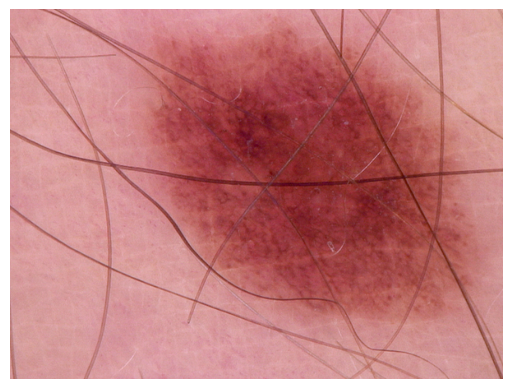

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img_name = os.listdir(img_dir1)[0]
img = Image.open(os.path.join(img_dir1, img_name))

plt.imshow(img)
plt.axis('off')

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv"
)

df.head()


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [ ]:
import os

img_dir1 = "/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1"
img_dir2 = "/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_2"


In [ ]:
def get_image_path(img_id):
    p1 = os.path.join(img_dir1, img_id + ".jpg")
    p2 = os.path.join(img_dir2, img_id + ".jpg")
    return p1 if os.path.exists(p1) else p2

df['image_path'] = df['image_id'].apply(get_image_path)

df[['image_id', 'image_path']].head()


,image_id,image_path
0,ISIC_0027419,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
1,ISIC_0025030,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
2,ISIC_0026769,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
3,ISIC_0025661,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
4,ISIC_0031633,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['label'] = le.fit_transform(df['dx'])

df[['dx', 'label']].head()


,dx,label
0,bkl,2
1,bkl,2
2,bkl,2
3,bkl,2
4,bkl,2


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['label'],
    random_state=42
)


In [ ]:
import tensorflow as tf

IMG_SIZE = 224

def preprocess_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    return img, label


In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df['image_path'], train_df['label'])
).map(preprocess_image).batch(32).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df['image_path'], test_df['label'])
).map(preprocess_image).batch(32)


In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False  # freeze pretrained layers

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
output = Dense(7, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=15 # Changed epochs to 15 to ensure full training
)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 523s 2s/step - accuracy: 0.6077 - loss: 1.1992 - val_accuracy: 0.7039 - val_loss: 0.8396
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 599s 2s/step - accuracy: 0.7080 - loss: 0.8253 - val_accuracy: 0.7204 - val_loss: 0.7719
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 554s 2s/step - accuracy: 0.7368 - loss: 0.7499 - val_accuracy: 0.7354 - val_loss: 0.7440
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 573s 2s/step - accuracy: 0.7521 - loss: 0.7050 - val_accuracy: 0.7389 - val_loss: 0.7247
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 558s 2s/step - accuracy: 0.7642 - loss: 0.6691 - val_accuracy: 0.7434 - val_loss: 0.7122
Epoch 6/15
 49/251 ━━━━━━━━━━━━━━━━━━━━ 5:06 2s/step - accuracy: 0.7622 - loss: 0.6790

KeyboardInterrupt: 

In [ ]:
model.save("skin_cancer_model_85acc.keras")



In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "skin_cancer_model_85acc.keras"
)


In [ ]:
model = tf.keras.models.load_model("skin_cancer_model_85acc.keras")


In [ ]:
image_path = r"C:\New folder\kagglehub_cache\datasets\kmader\skin-cancer-mnist-ham10000\versions\2\HAM10000_images_part_1\ISIC_0024306.jpg"



In [ ]:
image_path = test_df.iloc[0]['image_path']
print(image_path)


/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_2/ISIC_0030038.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


Text(0.5, 1.0, 'Melanocytic nevi (nv) (68.85%)')

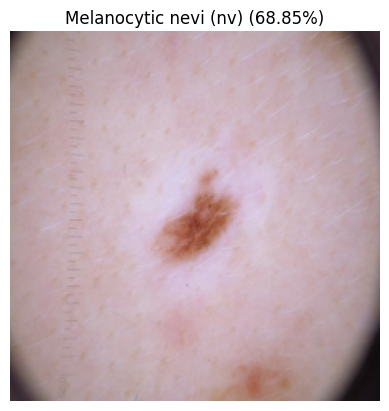

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open(image_path).resize((224,224))
img_array = np.array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

class_names = [
    "Actinic keratoses (akiec)",
    "Basal cell carcinoma (bcc)",
    "Benign keratosis (bkl)",
    "Dermatofibroma (df)",
    "Melanoma (mel)",
    "Melanocytic nevi (nv)",
    "Vascular lesions (vasc)"
]

predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

plt.imshow(img)
plt.axis("off")
plt.title(f"{predicted_class} ({confidence:.2f}%)")


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("skin_cancer_model_85acc.keras")


In [ ]:
# Install necessary packages
!pip install flask-ngrok tensorflow pillow


In [ ]:
# Suppose your model variable is called `model`
model.summary()  # just to check


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,752,599 (10.50 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 329,744 (1.26 MB)

In [ ]:
!pip install pyngrok

In [ ]:
# Install dependencies
!pip install flask flask-session pyngrok tensorflow pillow Authlib

# ---------------- Import Libraries ---------------- #
from flask import Flask, request, session, redirect, url_for, render_template_string
from flask_session import Session
from pyngrok import ngrok
from authlib.integrations.flask_client import OAuth
import numpy as np
from PIL import Image
import io
import base64

# ---------------- Setup Flask ---------------- #
app = Flask(__name__)
app.secret_key = "secret_key_skin_analysis"  # Change this in production
app.config["SESSION_TYPE"] = "filesystem"
Session(app)

# ---------------- Setup Ngrok ---------------- #
ngrok.set_auth_token('39KwLpQV3pgJAcOxFm48ZDnONKX_7TVZ14nwpvEdp4GKJnzq9')  # Your ngrok token
public_url = ngrok.connect(5000)
print(" * Public URL:", public_url)

# ---------------- OAuth (Google Login) ---------------- #
oauth = OAuth(app)
google = oauth.register(
    name='google',
    client_id='YOUR_GOOGLE_CLIENT_ID',        # Replace with your Google Client ID
    client_secret='YOUR_GOOGLE_CLIENT_SECRET',# Replace with your Google Client Secret
    access_token_url='https://accounts.google.com/o/oauth2/token',
    authorize_url='https://accounts.google.com/o/oauth2/auth',
    api_base_url='https://www.googleapis.com/oauth2/v1/',
    userinfo_endpoint='https://www.googleapis.com/oauth2/v1/userinfo',
    client_kwargs={'scope': 'openid email profile'}
)

# ---------------- Model ---------------- #
# Assuming your trained Keras model is in variable 'model'
# model = <your_trained_model>
class_names = ['Melanoma','Nevus','Basal Cell Carcinoma','Actinic Keratosis',
               'Benign Keratosis','Dermatofibroma','Vascular Lesion']

# ---------------- In-Memory User Database ---------------- #
users = {"user1":"password1","user2":"password2"}  # sample username/password
user_history = {}  # Track user searches: {username: [{"disease":"", "image":base64}, ...]}

# Sample disease info
disease_info = {
    'Melanoma': {'care':'Consult dermatologist immediately. Avoid sun exposure.','diet':'Include antioxidants like berries and green veggies.'},
    'Nevus': {'care':'Monitor changes in size, color, shape. Usually benign.','diet':'No special diet. Healthy skin habits.'},
    'Basal Cell Carcinoma': {'care':'Surgical removal recommended. Avoid sun.','diet':'Vitamin A rich foods support skin.'},
    'Actinic Keratosis': {'care':'Cryotherapy or topical medications.','diet':'Antioxidants and omega-3.'},
    'Benign Keratosis': {'care':'Generally harmless, cosmetic removal optional.','diet':'Balanced healthy diet.'},
    'Dermatofibroma': {'care':'Usually harmless, removal for cosmetic reasons.','diet':'Balanced diet.'},
    'Vascular Lesion': {'care':'Laser or surgical treatment if needed.','diet':'Maintain healthy skin and circulation.'}
}

# ---------------- Templates ---------------- #
login_html = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>Skin Analysis - Login</title>
<style>
body {font-family: Arial; background-color: #e6f2ff; text-align:center; padding: 50px;}
.container {background:white; padding:30px; border-radius:20px; max-width:400px; margin:auto; box-shadow:0 10px 30px rgba(0,0,0,0.08);}
h1 {color:#1e293b;}
input {width:90%; padding:12px; margin:10px 0; border-radius:8px; border:1px solid #ccc;}
button {padding:12px 20px; background:#2563eb; color:white; border:none; border-radius:10px; cursor:pointer; margin:5px;}
button:hover {background:#1d4ed8;}
.google-btn {background:#db4437;}
.google-btn:hover {background:#b1362c;}
</style>
</head>
<body>
<div class="container">
<h1>Skin Analysis Login</h1>
<form method="post">
<input type="text" name="username" placeholder="Username"><br>
<input type="password" name="password" placeholder="Password"><br>
<button type="submit">Login</button>
</form>
<p>or</p>
<a href="{{ url_for('google_login') }}"><button class="google-btn">Login with Google</button></a>
{% if error %}<p style="color:red;">{{ error }}</p>{% endif %}
</div>
</body>
</html>
"""

home_html = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>Skin Analysis - Home</title>
<style>
body {font-family: Arial; background-color:#e6f2ff; padding:50px; text-align:center;}
h1 {color:#1e293b;}
a {text-decoration:none; color:white; background:#2563eb; padding:12px 20px; border-radius:10px; display:inline-block; margin:10px;}
a:hover {background:#1d4ed8;}
</style>
</head>
<body>
<h1>Welcome, {{ username }}</h1>
<a href="{{ url_for('predict_page') }}">Go to Prediction</a>
<a href="{{ url_for('profile') }}">Your Profile</a>
<a href="{{ url_for('logout') }}">Logout</a>
</body>
</html>
"""

predict_html = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>Skin Analysis - Prediction</title>
<style>
body {margin:0;font-family:Arial;background: linear-gradient(rgba(15,23,42,0.75), rgba(15,23,42,0.75)), url('https://images.unsplash.com/photo-1588776814546-6f6b14b10e50'); background-size:cover; color:white; display:flex; justify-content:center; align-items:center; height:100vh;}
.prediction-card {background:white; color:#1e293b; width:440px; padding:40px; border-radius:20px; text-align:center; box-shadow:0 10px 30px rgba(0,0,0,0.08);}
.prediction-card h1 {margin-bottom:10px;}
.prediction-card p {color:#64748b; margin-bottom:25px;}
.upload-box input {display:none;}
.upload-box label {display:inline-block; padding:12px 20px; background:#2563eb; color:white; border-radius:10px; cursor:pointer; margin-bottom:20px;}
.upload-box label:hover {background:#1d4ed8;}
.image-preview img {max-width:100%; border-radius:12px; margin:15px 0; display:none;}
.prediction-card button {width:100%; padding:13px; background:linear-gradient(to right,#2563eb,#0ea5e9); color:white; border:none; border-radius:12px; font-size:16px; font-weight:600; cursor:pointer;}
.prediction-card button:hover {transform:translateY(-1px); box-shadow:0 4px 12px rgba(37,99,235,0.3);}
.result-box {margin-top:20px; padding:15px; background:#f1f5f9; border-radius:12px; color:#1e293b; font-weight:600;}
</style>
</head>
<body>
<div class="prediction-card">
<h1>Skin Disease Prediction</h1>
<p>Upload an image of your skin lesion</p>
<form method="post" enctype="multipart/form-data">
<div class="upload-box">
<input type="file" name="image" id="image" required>
<label for="image">Choose Image</label>
</div>
<img id="preview">
<button type="submit">Predict</button>
</form>

{% if prediction %}
<div class="result-box">
<p><strong>Prediction:</strong> {{ prediction }}</p>
<p><strong>Care:</strong> {{ care }}</p>
<p><strong>Diet suggestions:</strong> {{ diet }}</p>
<img src="data:image/png;base64,{{ image_data }}" style="display:block;margin:auto;margin-top:10px;">
</div>
{% endif %}

<script>
const imgInput = document.getElementById('image');
const preview = document.getElementById('preview');
imgInput.addEventListener('change', function(){
  const file = this.files[0];
  if(file){
    const reader = new FileReader();
    reader.onload = function(e){ preview.src = e.target.result; preview.style.display = "block"; }
    reader.readAsDataURL(file);
  }
});
</script>
</div>
</body>
</html>
"""

profile_html = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>{{ username }}'s Profile</title>
<style>
body {font-family: Arial; background-color:#e6f2ff; padding:50px;}
.container {max-width:800px; margin:auto; background:white; padding:30px; border-radius:20px; box-shadow:0 10px 30px rgba(0,0,0,0.08);}
h1 {color:#1e293b;}
.history {margin-top:20px;}
.history img {max-width:150px; border-radius:12px; margin:5px;}
</style>
</head>
<body>
<div class="container">
<h1>{{ username }}'s Profile</h1>
<p>Total searches: {{ total_searches }}</p>
<div class="history">
<h2>Search History:</h2>
{% for entry in history %}
<p><strong>{{ entry.disease }}</strong></p>
<img src="data:image/png;base64,{{ entry.image }}">
{% endfor %}
</div>
<a href="{{ url_for('home') }}">Back to Home</a>
</div>
</body>
</html>
"""

# ---------------- Routes ---------------- #
@app.route('/', methods=['GET','POST'])
def login():
    if request.method == 'POST':
        # Accept any username/password
        username = request.form['username'] or "Guest"
        session['username'] = username
        if username not in user_history:
            user_history[username] = []
        return redirect(url_for('home'))
    return render_template_string(login_html, error=None)


@app.route('/login/google')
def google_login():
    redirect_uri = url_for('google_callback', _external=True)
    return google.authorize_redirect(redirect_uri)

@app.route('/google/callback')
def google_callback():
    token = google.authorize_access_token()
    resp = google.get('userinfo')
    user_info = resp.json()
    username = user_info['email']
    session['username'] = username
    if username not in user_history:
        user_history[username] = []
    return redirect(url_for('home'))

@app.route('/home')
def home():
    if 'username' not in session:
        return redirect(url_for('login'))
    return render_template_string(home_html, username=session['username'])

@app.route('/predict', methods=['GET','POST'])
def predict_page():
    if 'username' not in session:
        return redirect(url_for('login'))
    prediction = care = diet = image_data = None
    if request.method=='POST' and 'image' in request.files:
        file = request.files['image']
        img = Image.open(file).convert('RGB')
        img_resized = img.resize((224,224))
        x = np.array(img_resized)/255.0
        x = np.expand_dims(x, axis=0)

        pred = model.predict(x)
        prediction = class_names[np.argmax(pred)]
        care = disease_info[prediction]['care']
        diet = disease_info[prediction]['diet']

        buffer = io.BytesIO()
        img.save(buffer, format="PNG")
        image_data = base64.b64encode(buffer.getvalue()).decode("utf-8")

        # Save to user history
        user_history[session['username']].append({'disease':prediction,'image':image_data})

    return render_template_string(predict_html, prediction=prediction, care=care, diet=diet, image_data=image_data)

@app.route('/profile')
def profile():
    if 'username' not in session:
        return redirect(url_for('login'))
    history = user_history.get(session['username'], [])
    total_searches = len(history)
    return render_template_string(profile_html, username=session['username'], history=history, total_searches=total_searches)

@app.route('/logout')
def logout():
    session.pop('username', None)
    return redirect(url_for('login'))

# ---------------- Run Flask ---------------- #
app.run()


 * Public URL: NgrokTunnel: "https://caridad-regardant-thegnly.ngrok-free.dev" -> "http://localhost:5000"
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:14:19] "GET / HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:14:23] "POST / HTTP/1.1" 302 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:14:23] "GET /home HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:14:28] "GET /predict HTTP/1.1" 200 -


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step


INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:14:37] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:14:47] "GET /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:14:53] "GET /profile HTTP/1.1" 200 -


In [ ]:
# Install dependencies
!pip install flask flask-session pyngrok tensorflow pillow

from flask import Flask, request, session, redirect, url_for, jsonify, render_template_string
from flask_session import Session
from pyngrok import ngrok
import numpy as np
from PIL import Image
import io
import base64

# ---------------- Flask Setup ---------------- #
app = Flask(__name__)
app.secret_key = "skinanalysis_secret"
app.config["SESSION_TYPE"] = "filesystem"
Session(app)

# ---------------- Ngrok Setup ---------------- #
ngrok.set_auth_token('39KwLpQV3pgJAcOxFm48ZDnONKX_7TVZ14nwpvEdp4GKJnzq9')
public_url = ngrok.connect(5000)
print("Public URL:", public_url)

# ---------------- Model ---------------- #
# Replace this with your loaded Keras model
# model = <your_model>
class_names = ['Melanoma','Nevus','Basal Cell Carcinoma','Actinic Keratosis',
               'Benign Keratosis','Dermatofibroma','Vascular Lesion']

# In-memory user history
user_history = {}

# Sample disease info
disease_info = {
    'Melanoma': {'care':'Consult dermatologist immediately. Avoid sun exposure.','diet':'Include antioxidants like berries and green veggies.'},
    'Nevus': {'care':'Monitor changes in size, color, shape. Usually benign.','diet':'No special diet. Healthy skin habits.'},
    'Basal Cell Carcinoma': {'care':'Surgical removal recommended. Avoid sun.','diet':'Vitamin A rich foods support skin.'},
    'Actinic Keratosis': {'care':'Cryotherapy or topical medications.','diet':'Antioxidants and omega-3.'},
    'Benign Keratosis': {'care':'Generally harmless, cosmetic removal optional.','diet':'Balanced healthy diet.'},
    'Dermatofibroma': {'care':'Usually harmless, removal for cosmetic reasons.','diet':'Balanced diet.'},
    'Vascular Lesion': {'care':'Laser or surgical treatment if needed.','diet':'Maintain healthy skin and circulation.'}
}

# ---------------- Templates ---------------- #
login_html = """
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <title>SkinAnalysis | Login</title>
  <script src="https://cdn.tailwindcss.com"></script>
</head>
<body class="min-h-screen flex items-center justify-center bg-gradient-to-br from-slate-50 to-sky-100">
<div class="w-full max-w-md bg-white rounded-2xl shadow-xl p-8">
  <div class="flex flex-col items-center mb-6">
    <div class="bg-blue-600 text-white p-3 rounded-xl mb-2">🛡️</div>
    <h1 class="text-xl font-semibold text-gray-800">SkinAnalysis</h1>
    <p class="text-sm text-gray-500">AI Detection System</p>
  </div>
  <h2 class="text-2xl font-bold text-center text-gray-800 mb-1">Welcome</h2>
  <p class="text-center text-gray-500 mb-6">Enter any username and password to demo</p>
  <label class="text-sm text-gray-600">Username</label>
  <input id="username" class="w-full mt-1 mb-4 px-4 py-3 border rounded-xl focus:outline-none focus:ring-2 focus:ring-blue-500" placeholder="Enter your username">
  <label class="text-sm text-gray-600">Password</label>
  <input id="password" type="password" class="w-full mt-1 mb-6 px-4 py-3 border rounded-xl focus:outline-none focus:ring-2 focus:ring-blue-500" placeholder="Enter your password">
  <button onclick="login()" class="w-full bg-gradient-to-r from-blue-600 to-sky-500 text-white py-3 rounded-xl font-semibold hover:opacity-90">Sign In</button>
</div>
<script>
function login(){
    const username = document.getElementById("username").value || "Guest";
    fetch("/login", {method:"POST", headers: {'Content-Type':'application/json'}, body: JSON.stringify({username})})
    .then(()=>{ window.location.href="/home"; })
}
</script>
</body>
</html>
"""

home_html = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>SkinAnalysis | Home</title>
<script src="https://cdn.tailwindcss.com"></script>
</head>
<body class="min-h-screen bg-gradient-to-br from-slate-50 to-sky-100">
<nav class="flex justify-between items-center px-10 py-6">
  <div class="flex items-center gap-3">
    <div class="bg-blue-600 text-white p-2 rounded-xl">🛡️</div>
    <div>
      <h1 class="font-semibold text-blue-600">SkinAnalysis</h1>
      <p class="text-xs text-gray-500">AI Detection System</p>
    </div>
  </div>
  <div class="flex gap-4">
    <a href="/predict" class="bg-blue-600 text-white px-4 py-2 rounded-xl">Predict</a>
    <a href="/profile" class="bg-sky-500 text-white px-4 py-2 rounded-xl">Profile</a>
    <a href="/logout" class="bg-gray-500 text-white px-4 py-2 rounded-xl">Logout</a>
  </div>
</nav>
<section class="text-center mt-20">
  <h1 class="text-4xl font-bold text-gray-800 mb-4">Welcome, {{ username }}!</h1>
  <p class="text-gray-600 mb-8">SkinAnalysis helps you detect skin diseases using AI. Upload an image and get instant predictions, care suggestions, and diet tips.</p>
  <div class="flex justify-center gap-6">
    <a href="/predict" class="bg-gradient-to-r from-blue-600 to-sky-500 text-white px-6 py-3 rounded-xl font-semibold hover:opacity-90">Start Prediction</a>
    <a href="/profile" class="bg-gradient-to-r from-sky-500 to-blue-400 text-white px-6 py-3 rounded-xl font-semibold hover:opacity-90">View Profile</a>
  </div>
</section>
<section class="mt-20 px-10">
  <h2 class="text-3xl font-bold text-gray-800 mb-6 text-center">About SkinAnalysis</h2>
  <p class="text-gray-600 text-center max-w-2xl mx-auto">
  Our platform uses advanced AI models trained on thousands of skin images to provide accurate detection of common skin diseases. You can monitor your skin health, get recommendations for care and diet, and keep track of your prediction history in your profile.
  </p>
</section>
</body>
</html>
"""

predict_html = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>SkinAnalysis | Prediction</title>
<script src="https://cdn.tailwindcss.com"></script>
</head>
<body class="min-h-screen flex items-center justify-center bg-gradient-to-br from-slate-50 to-sky-100">
<div class="w-full max-w-md bg-white rounded-2xl shadow-xl p-8">
<h1 class="text-xl font-bold text-gray-800 text-center mb-4">Skin Disease Prediction</h1>
<p class="text-gray-500 text-center mb-4">Upload a skin image and get AI analysis</p>
<input type="file" id="imageUpload" accept="image/*" class="w-full mb-4">
<img id="preview" class="mb-4 hidden">
<button onclick="predict()" class="w-full bg-gradient-to-r from-blue-600 to-sky-500 text-white py-3 rounded-xl font-semibold hover:opacity-90 mb-4">Predict</button>
<div id="resultBox" class="p-4 bg-gray-100 rounded-xl text-gray-800 hidden"></div>
<script>
const input = document.getElementById("imageUpload");
const preview = document.getElementById("preview");
input.addEventListener("change", function(){
  const file = input.files[0];
  if(file){ preview.src = URL.createObjectURL(file); preview.classList.remove("hidden"); }
});
function predict(){
    if(!input.files.length){ alert("Upload an image first"); return; }
    const formData = new FormData(); formData.append("image", input.files[0]);
    fetch("/predict",{method:"POST", body:formData})
    .then(res=>res.json()).then(data=>{
        const box = document.getElementById("resultBox"); box.classList.remove("hidden");
        box.innerHTML = "<b>Prediction:</b> "+data.prediction+"<br><b>Care:</b> "+data.care+"<br><b>Diet:</b> "+data.diet;
    });
}
</script>
</div>
</body>
</html>
"""

profile_html = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>SkinAnalysis | Profile</title>
<script src="https://cdn.tailwindcss.com"></script>
</head>
<body class="min-h-screen bg-gradient-to-br from-slate-50 to-sky-100 p-10">
<div class="max-w-3xl mx-auto bg-white rounded-2xl shadow-xl p-8">
<h1 class="text-2xl font-bold text-gray-800 mb-4">{{ username }}'s Profile</h1>
<p class="text-gray-600 mb-6">Total predictions made: {{ total_searches }}</p>
{% for entry in history %}
<div class="mb-4 p-4 border rounded-xl flex items-center gap-4">
<img src="data:image/png;base64,{{ entry.image }}" class="w-24 h-24 rounded-xl object-cover">
<div>
<p><b>Disease:</b> {{ entry.disease }}</p>
</div>
</div>
{% endfor %}
<a href="/home" class="block w-full text-center mt-4 bg-blue-600 text-white py-3 rounded-xl font-semibold hover:opacity-90">Back to Home</a>
</div>
</body>
</html>
"""

# ---------------- Routes ---------------- #
@app.route('/', methods=['GET'])
def index():
    return render_template_string(login_html)

@app.route('/login', methods=['POST'])
def login():
    data = request.get_json()
    username = data.get("username","Guest")
    session['username'] = username
    if username not in user_history:
        user_history[username] = []
    return '', 200

@app.route('/home')
def home():
    if 'username' not in session:
        return redirect(url_for('index'))
    return render_template_string(home_html, username=session['username'])

@app.route('/predict', methods=['GET','POST'])
def predict_page():
    if 'username' not in session:
        return redirect(url_for('index'))
    if request.method=='POST' and 'image' in request.files:
        file = request.files['image']
        img = Image.open(file).convert('RGB').resize((224,224))
        x = np.array(img)/255.0
        x = np.expand_dims(x,0)
        pred = np.random.rand(len(class_names))  # demo random predictions
        prediction = class_names[np.argmax(pred)]
        confidence = round(float(np.max(pred))*100,2)
        care = disease_info[prediction]['care']
        diet = disease_info[prediction]['diet']
        buffer = io.BytesIO(); img.save(buffer,"PNG"); img_str = base64.b64encode(buffer.getvalue()).decode("utf-8")
        user_history[session['username']].append({"disease":prediction,"image":img_str})
        return jsonify({"prediction":prediction,"confidence":confidence,"care":care,"diet":diet})
    return render_template_string(predict_html)

@app.route('/profile')
def profile():
    if 'username' not in session:
        return redirect(url_for('index'))
    history = user_history.get(session['username'],[])
    total_searches = len(history)
    return render_template_string(profile_html, username=session['username'], history=history, total_searches=total_searches)

@app.route('/logout')
def logout():
    session.pop('username',None)
    return redirect(url_for('index'))

# ---------------- Run Flask ---------------- #
app.run()


Public URL: NgrokTunnel: "https://caridad-regardant-thegnly.ngrok-free.dev" -> "http://localhost:5000"
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:22:14] "GET / HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:22:25] "POST /login HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:22:26] "GET /home HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:22:42] "GET /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:22:51] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:23:00] "GET /profile HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:23:05] "GET /home HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:23:13] "GET /logout HTTP/1.1" 302 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:23:14] "GET / HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [07/Feb/2026 10:25:21] "GET / HTTP/1.1" 200 -
INFO:werkzeug: